In [1]:
import cv2
from ultralytics import YOLO
import matplotlib.pyplot as plt
import torch
import numpy as np
import os



In [2]:
os.environ["KMP_DUPLICATE_LIB_OK"] = "TRUE"

In [3]:
print(torch.cuda.is_available())  # Dovrebbe restituire True
print(torch.cuda.device_count())  # Dovrebbe restituire il numero di GPU disponibili

print(torch.version.cuda)  # Mostra la versione di CUDA utilizzata da PyTorch
print(torch.backends.cudnn.version())  # Mostra la versione di cuDNN

True
1
11.8
90100


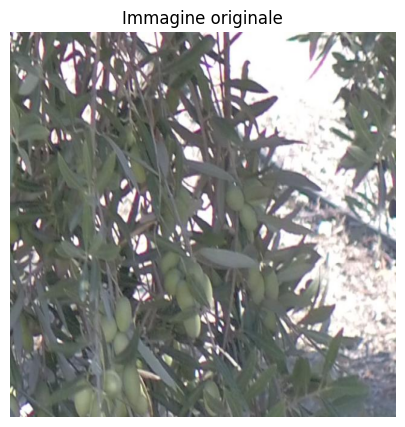

In [4]:
# Carica l'immagine originale
image_path = r'C:\Users\Bartolo\OlivesDetectionProject\neural_network\data\train_split\test\images\5a451135-4046-4b63-bbc8-94a81cbf933d_jpg.rf.b89356258f5b348ef81c1852b3e9c2a9.jpg'  # Specifica il percorso dell'immagine
image = cv2.imread(image_path)

cv2.imwrite(r'C:\Users\Bartolo\OlivesDetectionProject\neural_network\data\boxes_img.jpg', image)

# Visualizza il risultato finale
plt.figure(figsize=(10,5))
plt.imshow(cv2.cvtColor(image, cv2.COLOR_BGR2RGB))
plt.title("Immagine originale")
plt.axis('off')
plt.show()



image 1/1 C:\Users\Bartolo\OlivesDetectionProject\neural_network\data\train_split\test\images\5a451135-4046-4b63-bbc8-94a81cbf933d_jpg.rf.b89356258f5b348ef81c1852b3e9c2a9.jpg: 640x640 26 olives, 40.5ms
Speed: 3.0ms preprocess, 40.5ms inference, 79.4ms postprocess per image at shape (1, 3, 640, 640)


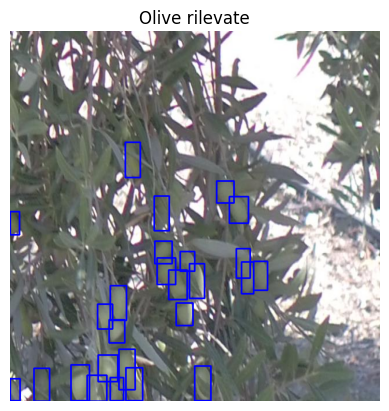

Numero totale di olive rilevate: 26
Weight totale stimato delle olive: 130 grammi


In [5]:
# Carica il modello YOLO
model = YOLO('yolov8m_olive_trained.pt')

# Definisci il weight medio di un'oliva in grammi
average_weight_per_olive = 5  # Modifica questo valore in base ai tuoi dati

# Esegui l'inferenza YOLO sull'immagine
results = model.predict(source=image_path, conf=0.5)  # Usa una soglia di confidenza adatta

# Variabile per il conteggio totale delle olive
total_olives = 0

# Ciclo sui risultati per elaborare le olive rilevate
for result in results:
    img_with_boxes = image.copy()  # Copia l'immagine per disegnare i bounding boxes
    boxes = result.boxes.xyxy  # Coordinate dei bounding boxes
    confidences = result.boxes.conf  # Confidenza dei bounding boxes
    
    total_olives += len(boxes)  # Incrementa il numero totale di olive rilevate
    
    # Disegna i bounding boxes e le etichette di confidenza
    for box, confidence in zip(boxes, confidences):
        x1, y1, x2, y2 = map(int, box[:4])  # Estrai le coordinate del bounding box
        cv2.rectangle(img_with_boxes, (x1, y1), (x2, y2), (255, 0, 0), 2)  # Colore rosso

# Calcola il weight totale stimato delle olive rilevate
total_weight = total_olives * average_weight_per_olive

# Converti l'immagine in RGB per visualizzazione
img_with_boxes_rgb = cv2.cvtColor(img_with_boxes, cv2.COLOR_BGR2RGB)

# Salva l'immagine con i bounding boxes e le etichette di confidenza
cv2.imwrite(r'C:\Users\Bartolo\OlivesDetectionProject\neural_network\data\boxes_with_confidence_img.jpg', img_with_boxes_rgb)

# Visualizza l'immagine con i bounding boxes e le etichette di confidenza
plt.imshow(img_with_boxes_rgb)
plt.title(f"Olives rilevate")
plt.axis('off')
plt.show()

# Stampa dei risultati finali
print(f"Numero totale di olive rilevate: {total_olives}")
print(f"Weight totale stimato delle olive: {total_weight} grammi")



image 1/1 C:\Users\Bartolo\OlivesDetectionProject\neural_network\data\train_split\test\images\5a451135-4046-4b63-bbc8-94a81cbf933d_jpg.rf.b89356258f5b348ef81c1852b3e9c2a9.jpg: 640x640 27 olives, 37.0ms
Speed: 8.7ms preprocess, 37.0ms inference, 10.0ms postprocess per image at shape (1, 3, 640, 640)


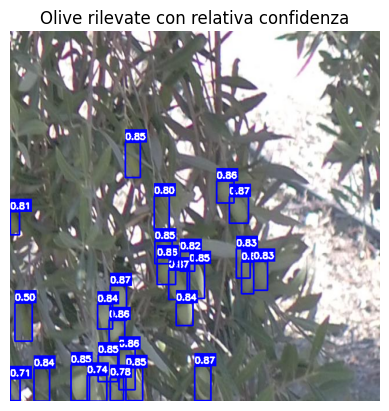

Numero totale di olive rilevate: 27


In [6]:
import cv2
import matplotlib.pyplot as plt
from ultralytics import YOLO
import numpy as np

# Carica il modello YOLO
model = YOLO('yolov8m_olive_trained.pt')

# Definisci il weight medio di un'oliva in grammi
average_weight_per_olive = 5  # Modifica questo valore in base ai tuoi dati

# Esegui l'inferenza YOLO sull'immagine
results = model.predict(source=image_path, conf=0.25)  # Usa una soglia di confidenza adatta

# Variabile per il conteggio totale delle olive
total_olives = 0

# Ciclo sui risultati per elaborare le olive rilevate
for result in results:
    img_with_boxes_and_conf = image.copy()  # Copia l'immagine per i bounding boxes e la confidenza
    boxes = result.boxes.xyxy  # Coordinate dei bounding boxes
    confs = result.boxes.conf  # Livelli di accuratezza per ogni box
    
    total_olives += len(boxes)  # Incrementa il numero totale di olive rilevate
    
    # Disegna i bounding boxes rossi e le etichette con sfondo rosso
    for box, conf in zip(boxes, confs):
        x1, y1, x2, y2 = map(int, box[:4])  # Estrai le coordinate del bounding box
        cv2.rectangle(img_with_boxes_and_conf, (x1, y1), (x2, y2), (255, 0, 0), 2)  # Colore rosso
        
        # Aggiungi il livello di confidenza con sfondo rosso
        label = f'{conf:.2f}'
        label_size, _ = cv2.getTextSize(label, cv2.FONT_HERSHEY_SIMPLEX, 0.5, 2)
        label_w, label_h = label_size

        # Disegna un rettangolo pieno come sfondo per l'etichetta
        cv2.rectangle(img_with_boxes_and_conf, (x1, y1 - label_h - 10), (x1 + label_w, y1), (255, 0, 0), -1)  # Rettangolo rosso
        # Scrivi l'etichetta sopra il rettangolo
        cv2.putText(img_with_boxes_and_conf, label, (x1, y1 - 5), cv2.FONT_HERSHEY_SIMPLEX, 0.5, (255, 255, 255), 2)  # Testo bianco

    # Converti l'immagine da BGR a RGB per matplotlib
    img_with_boxes_and_conf_rgb = cv2.cvtColor(img_with_boxes_and_conf, cv2.COLOR_BGR2RGB)

# Visualizza l'immagine con bounding boxes rosse e le etichette di confidenza
plt.imshow(img_with_boxes_and_conf_rgb)
plt.title("Olives rilevate con relativa confidenza")
plt.axis('off')
plt.show()

# Output del numero totale di olive rilevate
print(f"Numero totale di olive rilevate: {total_olives}")


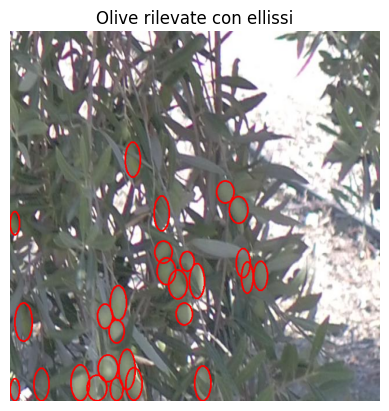

Numero totale di olive rilevate: 27
Weight totale stimato delle olive: 140.14 grammi


In [7]:
# Parametri per la stima del weight
total_weight = 0

# Funzione per stimare il weight basato sull'area dell'ellisse (usando bounding box)
def estimate_weight_from_bbox_ellipse(width, height):
    # Stima dell'area dell'ellisse contenuta nel bounding box
    area_ellipse = np.pi * width * height  # Usando l'area completa dell'ellisse
    
    # Coefficiente che rappresenta il weight per pixel quadrato (da stimare con dati campione)
    weight_per_pixel = 0.0012  # Modifica questo valore in base ai tuoi dati
    
    # Stima del weight in base all'area dell'ellisse
    estimated_weight = area_ellipse * weight_per_pixel
    
    return estimated_weight

# Ciclo per rilevare olive e disegnare le ellissi
for result in results:
    img_with_boxes = image.copy()  # Copia l'immagine per disegnare i bounding boxes e le ellissi
    boxes = result.boxes.xyxy  # Coordinate dei bounding boxes
    
    for box in boxes:
        x1, y1, x2, y2 = map(int, box[:4])  # Estrai le coordinate del bounding box
        width = x2 - x1
        height = y2 - y1
        
        # Stima il weight per questa oliva usando l'area dell'ellisse
        weight = estimate_weight_from_bbox_ellipse(width, height)
        total_weight += weight

        # Centro dell'ellisse
        center = (x1 + width // 2, y1 + height // 2)

        # Gli assi maggiore e minore sono la larghezza e l'altezza del bounding box
        axes = (width // 2, height // 2)

        # Disegna l'ellisse (usando il centro del bounding box e le dimensioni come assi)
        cv2.ellipse(img_with_boxes, center, axes, angle=0, startAngle=0, endAngle=360, color=(0, 0, 255), thickness=2)  # Colore rosso per l'ellisse

# Converti l'immagine in RGB per visualizzazione
img_with_boxes_rgb = cv2.cvtColor(img_with_boxes, cv2.COLOR_BGR2RGB)

# Salva l'immagine con i bounding boxes e le ellissi
cv2.imwrite(r'C:\Users\Bartolo\OlivesDetectionProject\neural_network\data\ellipses_img.jpg', img_with_boxes)

# Visualizza l'immagine con i bounding boxes e le ellissi
plt.imshow(img_with_boxes_rgb)
plt.title("Olives rilevate con ellissi")
plt.axis('off')
plt.show()

# Stampa del weight totale stimato
print(f"Numero totale di olive rilevate: {total_olives}")
print(f"Weight totale stimato delle olive: {total_weight:.2f} grammi")



image 1/1 C:\Users\Bartolo\OlivesDetectionProject\neural_network\data\train_split\test\images\5a451135-4046-4b63-bbc8-94a81cbf933d_jpg.rf.b89356258f5b348ef81c1852b3e9c2a9.jpg: 640x640 27 olives, 44.4ms
Speed: 2.5ms preprocess, 44.4ms inference, 4.1ms postprocess per image at shape (1, 3, 640, 640)


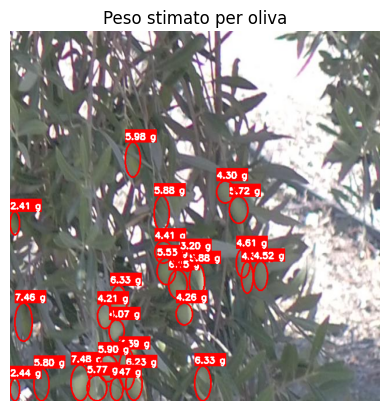

Weight totale stimato delle olive: 140.14 grammi


In [8]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

# Parametri per la stima del weight
total_weight = 0

# Funzione per stimare il weight basato sull'area dell'ellisse (usando bounding box)
def estimate_weight_from_bbox_ellipse(width, height):
    # Stima dell'area dell'ellisse contenuta nel bounding box
    area_ellipse = np.pi * width * height  # Usando l'area completa dell'ellisse
    
    # Coefficiente che rappresenta il weight per pixel quadrato (da stimare con dati campione)
    weight_per_pixel = 0.0012  # Modifica questo valore in base ai tuoi dati
    
    # Stima del weight in base all'area dell'ellisse
    estimated_weight = area_ellipse * weight_per_pixel
    
    return estimated_weight

# Esegui l'inferenza YOLO sull'immagine
results = model.predict(source=image_path, conf=0.25)  # Usa una soglia di confidenza adatta

# Ciclo per rilevare olive, disegnare le ellissi e aggiungere le etichette del weight
for result in results:
    img_with_boxes = image.copy()  # Copia l'immagine per disegnare i bounding boxes e le ellissi
    boxes = result.boxes.xyxy  # Coordinate dei bounding boxes
    
    for box in boxes:
        x1, y1, x2, y2 = map(int, box[:4])  # Estrai le coordinate del bounding box
        width = x2 - x1
        height = y2 - y1
        
        # Stima il weight per questa oliva usando l'area dell'ellisse
        weight = estimate_weight_from_bbox_ellipse(width, height)
        total_weight += weight

        # Centro dell'ellisse
        center = (x1 + width // 2, y1 + height // 2)

        # Gli assi maggiore e minore sono la larghezza e l'altezza del bounding box
        axes = (width // 2, height // 2)

        # Disegna l'ellisse (usando il centro del bounding box e le dimensioni come assi)
        cv2.ellipse(img_with_boxes, center, axes, angle=0, startAngle=0, endAngle=360, color=(0, 0, 255), thickness=2)  # Colore rosso per l'ellisse

        # Aggiungi lo sfondo blu per l'etichetta del weight
        label = f"{weight:.2f} g"  # Testo dell'etichetta con il weight stimato
        label_size, _ = cv2.getTextSize(label, cv2.FONT_HERSHEY_SIMPLEX, 0.5, 2)
        label_w, label_h = label_size

        # Disegna un rettangolo blu per l'etichetta del weight
        cv2.rectangle(img_with_boxes, (x1, y1 - label_h - 10), (x1 + label_w, y1), (0, 0, 255), -1)  # Rosso
        # Aggiungi il testo bianco sopra lo sfondo blu
        cv2.putText(img_with_boxes, label, (x1, y1 - 5), cv2.FONT_HERSHEY_SIMPLEX, 0.5, (255, 255, 255), 2)  # Testo bianco

# Converti l'immagine in RGB per visualizzazione
img_with_boxes_rgb = cv2.cvtColor(img_with_boxes, cv2.COLOR_BGR2RGB)

# Salva l'immagine con i bounding boxes, le ellissi e le etichette del weight
cv2.imwrite(r'C:\Users\Bartolo\OlivesDetectionProject\neural_network\data\ellipses_with_weights_img.jpg', img_with_boxes)

# Visualizza l'immagine con i bounding boxes, le ellissi e le etichette del weight
plt.imshow(img_with_boxes_rgb)
plt.title("Weight stimato per oliva")
plt.axis('off')
plt.show()

# Stampa del weight totale stimato
print(f"Weight totale stimato delle olive: {total_weight:.2f} grammi")


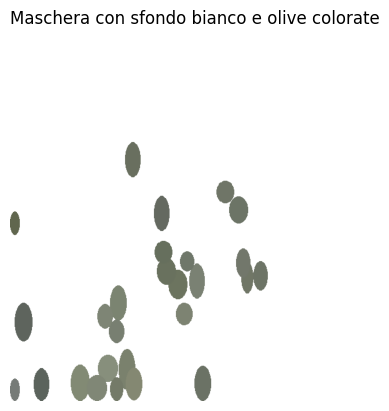


image 1/1 C:\Users\Bartolo\OlivesDetectionProject\neural_network\data\train_split\test\images\5a451135-4046-4b63-bbc8-94a81cbf933d_jpg.rf.b89356258f5b348ef81c1852b3e9c2a9.jpg: 640x640 27 olives, 34.6ms
Speed: 5.5ms preprocess, 34.6ms inference, 10.5ms postprocess per image at shape (1, 3, 640, 640)
Olives verdi: 27
Olives nere: 0
Olives miste: 0


In [9]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

# Funzione per calcolare il colore medio all'interno dell'ellisse
def calculate_average_color(image, center, axes):
    mask = np.zeros(image.shape[:2], dtype=np.uint8)  # Crea una maschera vuota
    # Disegna un'ellisse bianca (255) sulla maschera
    cv2.ellipse(mask, center, axes, 0, 0, 360, 255, -1)
    
    # Applica la maschera all'immagine per isolare l'ellisse
    masked_img = cv2.bitwise_and(image, image, mask=mask)
    
    # Calcola il colore medio all'interno dell'ellisse
    mean_color = cv2.mean(image, mask=mask)[:3]  # Solo i primi tre valori (BGR), ignora il canale alpha
    
    return mean_color

# Funzione per creare la maschera con sfondo bianco e olive con colore medio
def create_mask_with_olive_colors(image, results):
    mask = np.full_like(image, 255)  # Maschera bianca (sfondo)

    # Ciclo per disegnare le ellissi e riempirle con il colore medio
    for result in results:
        boxes = result.boxes.xyxy  # Coordinate dei bounding boxes
        
        for box in boxes:
            x1, y1, x2, y2 = map(int, box[:4])  # Estrai le coordinate del bounding box
            width = x2 - x1
            height = y2 - y1

            # Centro dell'ellisse
            center = (x1 + width // 2, y1 + height // 2)

            # Gli assi maggiore e minore sono la larghezza e l'altezza del bounding box
            axes = (width // 2, height // 2)

            # Calcola il colore medio all'interno dell'ellisse
            average_color = calculate_average_color(image, center, axes)
            average_color_bgr = tuple(map(int, average_color))  # Converti i valori del colore in interi
            
            # Riempi l'ellisse con il colore medio calcolato
            cv2.ellipse(mask, center, axes, 0, 0, 360, average_color_bgr, -1)

    return mask

# Crea la maschera con sfondo bianco e le olive con il loro colore medio
mask_with_olive_colors = create_mask_with_olive_colors(image, results)

# Visualizza la maschera con sfondo bianco e olive colorate
plt.imshow(cv2.cvtColor(mask_with_olive_colors, cv2.COLOR_BGR2RGB))
plt.title("Maschera con sfondo bianco e olive colorate")
plt.axis('off')
plt.show()

# Salva la maschera come immagine
cv2.imwrite(r'C:\Users\Bartolo\OlivesDetectionProject\neural_network\data\mask_with_olive_colors.jpg', mask_with_olive_colors)

import cv2
import numpy as np
import matplotlib.pyplot as plt

# Definizione dei range di colore in formato HSV
def define_color_ranges():
    # Olives verdi (spettro di colori dal verde al giallo)
    verde_lower = np.array([35, 40, 40])
    verde_upper = np.array([90, 255, 255])
    
    # Olives nere (spettro di colori dal rosso scuro, viola al nero)
    nero_lower = np.array([0, 0, 0])
    nero_upper = np.array([179, 255, 60])
    
    # Olives miste (valori intermedi tra verde e nero)
    misto_lower = np.array([15, 40, 40])
    misto_upper = np.array([35, 255, 255])
    
    return verde_lower, verde_upper, nero_lower, nero_upper, misto_lower, misto_upper

# Funzione per contare il numero di olive verdi, nere e miste
def count_olive_colors(mask, results):
    # Converti la maschera in formato HSV
    hsv_mask = cv2.cvtColor(mask, cv2.COLOR_BGR2HSV)
    
    # Definisci i range di colore
    verde_lower, verde_upper, nero_lower, nero_upper, misto_lower, misto_upper = define_color_ranges()

    # Contatori per olive verdi, nere e miste
    green_count = 0
    black_count = 0
    mixed_count = 0

    # Ciclo per ogni oliva e classifica in base al colore medio
    for result in results:
        boxes = result.boxes.xyxy  # Coordinate dei bounding boxes
        
        for box in boxes:
            x1, y1, x2, y2 = map(int, box[:4])  # Estrai le coordinate del bounding box
            width = x2 - x1
            height = y2 - y1

            # Centro dell'ellisse
            center = (x1 + width // 2, y1 + height // 2)

            # Gli assi maggiore e minore sono la larghezza e l'altezza del bounding box
            axes = (width // 2, height // 2)

            # Crea una maschera ellittica per l'oliva
            mask_ellipse = np.zeros(hsv_mask.shape[:2], dtype=np.uint8)
            cv2.ellipse(mask_ellipse, center, axes, 0, 0, 360, 255, -1)
            
            # Applica la maschera ellittica alla maschera HSV
            masked_olive_hsv = cv2.bitwise_and(hsv_mask, hsv_mask, mask=mask_ellipse)

            # Calcola il colore medio dell'oliva nell'ellisse
            mean_color_hsv = cv2.mean(masked_olive_hsv, mask=mask_ellipse)[:3]
            
            # Classifica il colore dell'oliva in base ai range
            if verde_lower[0] <= mean_color_hsv[0] <= verde_upper[0]:
                green_count += 1
            elif nero_lower[0] <= mean_color_hsv[0] <= nero_upper[0]:
                black_count += 1
            elif misto_lower[0] <= mean_color_hsv[0] <= misto_upper[0]:
                mixed_count += 1

    return green_count, black_count, mixed_count

# Esegui l'inferenza YOLO sull'immagine
results = model.predict(source=image_path, conf=0.25)  # Usa una soglia di confidenza adatta

# Crea la maschera con sfondo bianco e le olive con il loro colore medio
mask_with_olive_colors = create_mask_with_olive_colors(image, results)

# Conta il numero di olive verdi, nere e miste
green_olives, black_olives, mixed_olives = count_olive_colors(mask_with_olive_colors, results)

# Output del conteggio
print(f"Olives verdi: {green_olives}")
print(f"Olives nere: {black_olives}")
print(f"Olives miste: {mixed_olives}")



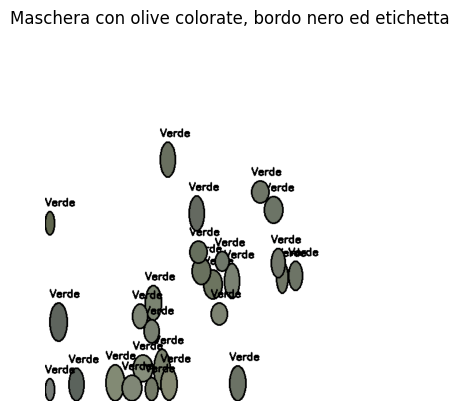

True

In [10]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

# Definizione dei range di colore in formato HSV
def define_color_ranges():
    # Olives verdi (spettro di colori dal verde al giallo)
    verde_lower = np.array([35, 40, 40])
    verde_upper = np.array([90, 255, 255])
    
    # Olives nere (spettro di colori dal rosso scuro, viola al nero)
    nero_lower = np.array([0, 0, 0])
    nero_upper = np.array([179, 255, 60])
    
    # Olives miste (valori intermedi tra verde e nero)
    misto_lower = np.array([15, 40, 40])
    misto_upper = np.array([35, 255, 255])
    
    return verde_lower, verde_upper, nero_lower, nero_upper, misto_lower, misto_upper

# Funzione per calcolare il colore medio all'interno dell'ellisse
def calculate_average_color(image, center, axes):
    mask = np.zeros(image.shape[:2], dtype=np.uint8)  # Crea una maschera vuota
    # Disegna un'ellisse bianca (255) sulla maschera
    cv2.ellipse(mask, center, axes, 0, 0, 360, 255, -1)
    
    # Applica la maschera all'immagine per isolare l'ellisse
    masked_img = cv2.bitwise_and(image, image, mask=mask)
    
    # Calcola il colore medio all'interno dell'ellisse
    mean_color = cv2.mean(image, mask=mask)[:3]  # Solo i primi tre valori (BGR), ignora il canale alpha
    
    return mean_color

# Funzione per classificare il colore dell'oliva
def classify_olive_color(mean_color_hsv):
    verde_lower, verde_upper, nero_lower, nero_upper, misto_lower, misto_upper = define_color_ranges()

    if verde_lower[0] <= mean_color_hsv[0] <= verde_upper[0]:
        return "Verde"
    elif nero_lower[0] <= mean_color_hsv[0] <= nero_upper[0]:
        return "Nera"
    elif misto_lower[0] <= mean_color_hsv[0] <= misto_upper[0]:
        return "Mista"
    return "Non classificata"

# Funzione per creare la maschera con sfondo bianco, olive con colore medio, bordo nero, ed etichetta di classificazione
def create_mask_with_olive_colors_borders_and_labels(image, results):
    mask = np.full_like(image, 255)  # Maschera bianca (sfondo)

    # Ciclo per disegnare le ellissi, riempirle con il colore medio e aggiungere etichette
    for result in results:
        boxes = result.boxes.xyxy  # Coordinate dei bounding boxes
        
        for box in boxes:
            x1, y1, x2, y2 = map(int, box[:4])  # Estrai le coordinate del bounding box
            width = x2 - x1
            height = y2 - y1

            # Centro dell'ellisse
            center = (x1 + width // 2, y1 + height // 2)

            # Gli assi maggiore e minore sono la larghezza e l'altezza del bounding box
            axes = (width // 2, height // 2)

            # Calcola il colore medio all'interno dell'ellisse
            average_color = calculate_average_color(image, center, axes)
            average_color_bgr = tuple(map(int, average_color))  # Converti i valori del colore in interi
            
            # Riempi l'ellisse con il colore medio calcolato
            cv2.ellipse(mask, center, axes, 0, 0, 360, average_color_bgr, -1)

            # Disegna il bordo nero intorno all'ellisse
            cv2.ellipse(mask, center, axes, 0, 0, 360, (0, 0, 0), 2)  # Bordi neri

            # Converti il colore medio da BGR a HSV per la classificazione
            average_color_hsv = cv2.cvtColor(np.uint8([[average_color_bgr]]), cv2.COLOR_BGR2HSV)[0][0]

            # Classifica il colore dell'oliva
            color_class = classify_olive_color(average_color_hsv)

            # Aggiungi l'etichetta con la classificazione del colore sopra l'oliva
            label_position = (x1, y1 - 10)  # Posizione dell'etichetta sopra il bounding box
            cv2.putText(mask, color_class, label_position, cv2.FONT_HERSHEY_SIMPLEX, 0.6, (0, 0, 0), 2)  # Testo nero

    return mask


# Crea la maschera con sfondo bianco, olive con colore medio, bordo nero ed etichetta di classificazione
mask_with_olive_colors_borders_and_labels = create_mask_with_olive_colors_borders_and_labels(image, results)

# Visualizza la maschera con sfondo bianco, olive colorate, bordo nero e etichetta
plt.imshow(cv2.cvtColor(mask_with_olive_colors_borders_and_labels, cv2.COLOR_BGR2RGB))
plt.title("Maschera con olive colorate, bordo nero ed etichetta")
plt.axis('off')
plt.show()

# Salva la maschera come immagine
cv2.imwrite(r'C:\Users\Bartolo\OlivesDetectionProject\neural_network\data\mask_with_olive_colors_borders_and_labels.jpg', mask_with_olive_colors_borders_and_labels)
